# Etapa 1: Análise exploratória da base NSL-KDD modificada

O objetivo desta etapa é conhecer os dados antes de treinar qualquer modelo: entender como a base está organizada, encontrar problemas nos dados (valores ausentes, inconsistências, redundâncias) e identificar atributos que podem causar vazamento de informação. O notebook termina com um diagnóstico que orienta o pré-processamento da Etapa 2.

A base é uma versão do NSL-KDD, de detecção de intrusão em redes, modificada para a competição da disciplina. Cada linha representa uma conexão de rede, e a coluna `class` indica se ela é `normal` ou `anomaly`. A métrica usada no ranking é o F1-macro.

O arquivo de teste não tem rótulo e foi usado aqui apenas para comparar características com o treino (ausentes, valores inválidos e categorias). Nenhuma transformação foi ajustada com base nele.

Seções: 1. Caracterização; 2. Classes e desbalanceamento; 3. Atributos categóricos; 4. Inconsistências; 5. Redundâncias; 6. Possíveis vazamentos; 7. Diagnóstico.

## 0. Leitura dos dados

In [ ]:
# [IA] Pastas do projeto: este notebook fica na pasta da sua etapa, e os dados
# (BANCO_DE_DADOS/) e o código (codigo/) ficam na pasta principal do projeto.
import os, sys
from pathlib import Path
PASTA_NOTEBOOK = Path.cwd()
if not Path("BANCO_DE_DADOS").is_dir():
    os.chdir(PASTA_NOTEBOOK.parent)
sys.path.insert(0, str(Path("codigo").resolve()))
print("pasta do projeto:", Path.cwd().name, "| notebook em:", PASTA_NOTEBOOK.name)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

# os dois arquivos ficam na pasta BANCO_DE_DADOS
PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino.csv")
teste = pd.read_csv(PASTA / "teste_sem_rotulo.csv")

ALVO = "class"
CAT = ["protocol_type", "service", "flag", "tipo_alerta_soc"]   # as colunas que são texto
# as 8 colunas a mais, que não existem no NSL-KDD original
NOVAS = ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod",
         "score_ids_legado", "tipo_alerta_soc", "tempo_resposta_analista_min"]
NUM = [c for c in treino.columns if c not in CAT + [ALVO]]
TAXAS = [c for c in NUM if c.endswith("_rate")]

# deixo a classe em 0 e 1 porque várias contas abaixo precisam dela assim (1 = anomaly)
y = (treino[ALVO] == "anomaly").astype(int)

print("treino:", treino.shape, "| teste:", teste.shape)
print("Colunas só no treino:", sorted(set(treino.columns) - set(teste.columns)))
print("Colunas só no teste:", sorted(set(teste.columns) - set(treino.columns)))

treino: (69833, 50) | teste: (24333, 50)
Colunas só no treino: ['class']
Colunas só no teste: ['id']


## 1. Caracterização dos dados

Nesta seção verificamos o tamanho das bases, o tipo de cada coluna e a quantidade de valores ausentes. A quantidade e a localização dos ausentes definem como eles serão tratados (imputação, remoção da coluna ou criação de um indicador).

In [2]:
# uma visão geral das duas bases lado a lado
resumo = pd.DataFrame({
    "linhas": [len(treino), len(teste)],
    "colunas": [treino.shape[1], teste.shape[1]],
    "numéricas": [treino.select_dtypes("number").shape[1], teste.select_dtypes("number").shape[1]],
    "texto": [treino.select_dtypes(exclude="number").shape[1], teste.select_dtypes(exclude="number").shape[1]],
    "linhas com algum ausente": [treino.isna().any(axis=1).sum(), teste.isna().any(axis=1).sum()],
}, index=["treino", "teste"])
display(resumo)

print("Colunas de texto no treino:", list(treino.select_dtypes(exclude="number").columns))
print("Colunas de texto no teste:", list(teste.select_dtypes(exclude="number").columns))
print("\nTipos das colunas numéricas (treino):")
print(treino.select_dtypes("number").dtypes.value_counts().to_string())

,linhas,colunas,numéricas,texto,linhas com algum ausente
treino,69833,50,45,5,69512
teste,24333,50,46,4,24224


Colunas de texto no treino: ['protocol_type', 'service', 'flag', 'tipo_alerta_soc', 'class']
Colunas de texto no teste: ['protocol_type', 'service', 'flag', 'tipo_alerta_soc']

Tipos das colunas numéricas (treino):
float64    32
int64      13


In [3]:
# quanto falta em cada coluna, em número e em %, comparando treino e teste
aus = pd.DataFrame({
    "treino_n": treino.isna().sum(),
    "treino_%": treino.isna().mean() * 100,
    "teste_n": teste.isna().sum().reindex(treino.columns).astype("Int64"),
    "teste_%": teste.isna().mean().reindex(treino.columns) * 100,
})
aus = aus[(aus["treino_n"] > 0) | (aus["teste_n"] > 0)].sort_values("treino_%", ascending=False)
display(aus)

print("Colunas com ausentes no treino:", (treino.isna().sum() > 0).sum(), "| no teste:", (teste.isna().sum() > 0).sum())
print("Maior diferença entre treino e teste (pontos percentuais):", round((aus["treino_%"] - aus["teste_%"]).abs().max(), 2))

,treino_n,treino_%,teste_n,teste_%
tempo_resposta_analista_min,63804,91.366546,22533,92.602638
src_bytes,27906,39.961050,9859,40.516993
src_bytes_kb,27906,39.961050,9859,40.516993
total_bytes,27906,39.961050,9859,40.516993
dst_host_srv_count,27844,39.872267,9567,39.316977
dst_host_serror_rate,21393,30.634514,7356,30.230551
dst_host_same_src_port_rate,19543,27.985336,6848,28.142851
serror_rate,4734,6.779030,1630,6.698722
service,4416,6.323658,1528,6.279538
logged_in,4250,6.085948,1444,5.934328


Colunas com ausentes no treino: 28 | no teste: 28
Maior diferença entre treino e teste (pontos percentuais): 1.24


In [4]:
# agora a mesma coisa separando por classe (só dá pra fazer no treino, o teste não tem rótulo)
aus_cls = treino.drop(columns=ALVO).isna().groupby(treino[ALVO]).mean().T * 100
aus_cls = aus_cls[(aus_cls > 0).any(axis=1)]
aus_cls["diferença (anomaly - normal)"] = aus_cls["anomaly"] - aus_cls["normal"]
display(aus_cls.sort_values("diferença (anomaly - normal)", key=abs, ascending=False))

class,anomaly,normal,diferença (anomaly - normal)
tempo_resposta_analista_min,23.535180,95.574414,-72.039234
dst_host_serror_rate,44.839421,29.753323,15.086098
dst_host_same_src_port_rate,26.526109,28.075859,-1.549749
src_bytes,38.955626,40.023421,-1.067794
src_bytes_kb,38.955626,40.023421,-1.067794
total_bytes,38.955626,40.023421,-1.067794
num_file_creations,5.957342,5.315266,0.642076
count,4.780583,5.366974,-0.586390
dst_host_srv_rerror_rate,4.216720,4.754083,-0.537364
srv_diff_host_rate,5.638637,6.109134,-0.470497


Se a porcentagem de ausentes for parecida nas duas classes, a falta de valor é aleatória e pode ser tratada com imputação. Se for muito diferente, a própria ausência traz informação sobre a classe, o que é discutido na seção 6.

**Conclusão da seção 1**

- O treino tem 69.833 linhas e o teste, 24.333, ambos com 50 colunas. A diferença é que o treino tem a coluna `class` e o teste tem a coluna `id`.
- 28 colunas têm valores ausentes, nas duas bases, em proporções muito parecidas (a maior diferença entre treino e teste é de 1,24 ponto percentual).
- Algumas colunas têm muitos ausentes: `tempo_resposta_analista_min` (91,4% no treino), `src_bytes` (40,0%), `dst_host_srv_count` (39,9%), `dst_host_serror_rate` (30,6%) e `dst_host_same_src_port_rate` (28,0%). Nas demais, a proporção fica entre 3,5% e 6,8%.
- Na maioria das colunas a proporção de ausentes é igual nas duas classes. As exceções são `tempo_resposta_analista_min` (95,6% ausente nas normais e 23,5% nas anomalias) e `dst_host_serror_rate` (29,8% e 44,8%).

Os ausentes precisarão ser imputados na Etapa 2, com a imputação ajustada apenas no treino. As duas exceções são analisadas na seção 6.

## 2. Classes e desbalanceamento

Aqui verificamos quantas conexões são normais e quantas são anomalias. Quando uma classe é muito mais rara que a outra, a acurácia deixa de ser uma boa medida, e isso afeta a escolha da métrica e da validação.

,contagem,proporção (%)
class,,
normal,65754,94.158922
anomaly,4079,5.841078


Razão normal:anomaly = 16.1 : 1


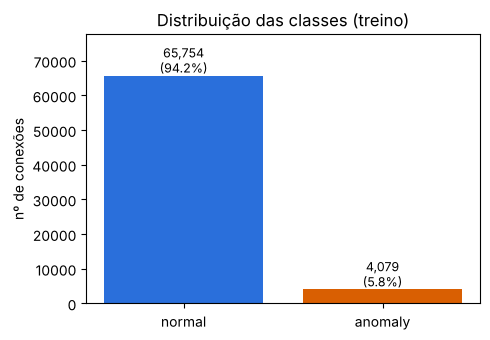

In [5]:
# quantas conexões de cada classe
cont = treino[ALVO].value_counts()
prop = treino[ALVO].value_counts(normalize=True) * 100
display(pd.DataFrame({"contagem": cont, "proporção (%)": prop}))
print(f"Razão normal:anomaly = {cont['normal'] / cont['anomaly']:.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(cont.index, cont.values, color=[AZUL, LARANJA])
for b, v, p in zip(barras, cont.values, prop.values):   # escreve o número em cima de cada barra
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, cont.max() * 1.18)
ax.set_ylabel("nº de conexões")
ax.set_title("Distribuição das classes (treino)")
plt.tight_layout(); plt.show()

In [6]:
# o que acontece se um "modelo" chutar sempre normal? serve pra mostrar por que a acurácia engana aqui
sempre_normal = np.zeros(len(y), dtype=int)
print(f"Acurácia: {accuracy_score(y, sempre_normal):.4f}")
print(f"F1-macro: {f1_score(y, sempre_normal, average='macro'):.4f}")
print("F1 por classe (normal, anomaly):", np.round(f1_score(y, sempre_normal, average=None, zero_division=0), 4))

Acurácia: 0.9416
F1-macro: 0.4850
F1 por classe (normal, anomaly): [0.9699 0.    ]


O F1-macro calcula o F1 de cada classe e tira a média simples entre elas. Assim, errar as anomalias pesa tanto quanto errar as conexões normais, mesmo sendo uma classe bem menor.

**Conclusão da seção 2**

- As classes são muito desbalanceadas: 65.754 conexões normais (94,2%) e 4.079 anomalias (5,8%), cerca de 16 normais para cada anomalia.
- Um classificador que responde sempre "normal" teria acurácia de 0,9416, mas F1-macro de apenas 0,4850, porque o F1 da classe `anomaly` seria zero.

Para as próximas etapas, a validação deve ser estratificada (mantendo a proporção das classes em cada fold), e técnicas de balanceamento ou de ponderação das classes devem ser aplicadas apenas dentro do treino de cada fold. Também vale ajustar o limiar de decisão pensando no F1-macro.

## 3. Atributos categóricos

Os atributos `protocol_type`, `service` e `flag` são texto. Um problema comum nesse tipo de coluna é o mesmo valor aparecer escrito de formas diferentes (por exemplo, `tcp` e `TCP`), o que faria o modelo tratá-los como categorias distintas. Verificamos a quantidade de valores, as grafias diferentes e se o teste tem as mesmas categorias do treino.

In [7]:
# tira os espaços das pontas e deixa tudo minúsculo, pra comparar grafias
def norm(s):
    return s.str.strip().str.lower()

linhas = []
for col in ["protocol_type", "service", "flag"]:
    for nome, df in [("treino", treino), ("teste", teste)]:
        s = df[col].dropna()
        # considero "certa" a grafia mais comum de cada valor; o resto conta como grafia diferente
        canon = s.groupby(norm(s)).agg(lambda v: v.value_counts().idxmax())
        fora = (s != norm(s).map(canon)).sum()
        linhas.append({"coluna": col, "base": nome, "ausentes": int(df[col].isna().sum()),
                       "distintos (bruto)": s.nunique(), "distintos (normalizado)": norm(s).nunique(),
                       "com espaço nas pontas": int((s != s.str.strip()).sum()),
                       "linhas com grafia diferente": int(fora)})
display(pd.DataFrame(linhas))

,coluna,base,ausentes,distintos (bruto),distintos (normalizado),com espaço nas pontas,linhas com grafia diferente
0,protocol_type,treino,0,6,3,0,1455
1,protocol_type,teste,0,3,3,0,0
2,service,treino,4416,96,67,1292,1292
3,service,teste,1528,65,65,0,0
4,flag,treino,4093,19,11,0,1340
5,flag,teste,1483,11,11,0,0


In [8]:
# olhando de perto quais grafias aparecem pra cada valor
for col in ["protocol_type", "flag"]:
    print(f"{col}: contagem por grafia (treino)")
    print(treino[col].value_counts(dropna=False).to_string(), "\n")

s = treino["service"].dropna()
variantes = s.groupby(norm(s)).agg(lambda v: v.value_counts().to_dict())
variantes = variantes[variantes.map(len) > 1]
print(f"service: {len(variantes)} serviços aparecem com mais de uma grafia. Alguns exemplos:")
print(variantes.head(8).to_string())

protocol_type: contagem por grafia (treino)
protocol_type
tcp     54824
udp     11940
icmp     1614
TCP      1186
UDP       240
ICMP       29 

flag: contagem por grafia (treino)
flag
SF        58058
NaN        4093
REJ        2856
S0         2399
sf         1220
RSTR        328
S1          288
RSTO        287
S2          103
rej          61
S3           52
s0           33
SH           19
rstr         10
OTH           8
s2            6
rsto          4
s1            4
s3            2
RSTOS0        2 

service: 29 serviços aparecem com mais de uma grafia. Alguns exemplos:
service
auth                   {'auth': 227, 'auth ': 4}
bgp                       {'bgp': 35, 'bgp ': 2}
ctf                       {'ctf': 40, 'ctf ': 2}
domain_u    {'domain_u': 7497, 'domain_u ': 174}
eco_i                {'eco_i': 593, 'eco_i ': 8}
ecr_i                {'ecr_i': 341, 'ecr_i ': 1}
exec                    {'exec': 16, 'exec ': 1}
finger            {'finger': 557, 'finger ': 11}


In [9]:
# a grafia diferente aparece mais em alguma classe? se aparecesse, seria uma pista indevida
s = treino["protocol_type"]
maiuscula = s.notna() & (s != s.str.lower())
print("protocol_type com maiúsculas, por classe (%):")
print(pd.crosstab(maiuscula, treino[ALVO], normalize="columns").mul(100).round(2))

# e depois de padronizar, sobra alguma categoria que só existe numa das bases?
for col in ["protocol_type", "service", "flag"]:
    a, b = set(norm(treino[col].dropna())), set(norm(teste[col].dropna()))
    print(f"\n{col}: só no teste = {sorted(b - a)} | só no treino = {sorted(a - b)}")

protocol_type com maiúsculas, por classe (%):
class          anomaly  normal
protocol_type                 
False            97.74   97.93
True              2.26    2.07

protocol_type: só no teste = [] | só no treino = []

service: só no teste = [] | só no treino = ['http_2784', 'shell']

flag: só no teste = [] | só no treino = []


In [10]:
# comparando a frequência das categorias entre treino e teste (já padronizadas)
for col in ["protocol_type", "flag"]:
    comp = pd.DataFrame({"treino_%": norm(treino[col]).value_counts(normalize=True) * 100,
                         "teste_%": norm(teste[col]).value_counts(normalize=True) * 100}).fillna(0)
    print(col)
    display(comp)

top = norm(treino["service"]).value_counts(normalize=True).head(6) * 100
print("Os 6 serviços mais comuns no treino (%):")
print(top.round(2).to_string())
print("Os mesmos serviços no teste (%):")
print((norm(teste["service"]).value_counts(normalize=True) * 100).reindex(top.index).round(2).to_string())

protocol_type


,treino_%,teste_%
protocol_type,,
tcp,80.205633,79.842190
udp,17.441611,17.831751
icmp,2.352756,2.326059


flag


,treino_%,teste_%
flag,,
oth,0.012169,0.013129
rej,4.437177,4.210066
rsto,0.442653,0.407002
rstos0,0.003042,0.017505
rstr,0.514147,0.490153
s0,3.699422,2.997812
s1,0.444174,0.450766
s2,0.165805,0.166302
s3,0.082142,0.061269


Os 6 serviços mais comuns no treino (%):
service
http        55.36
domain_u    11.73
smtp         9.28
ftp_data     6.53
private      4.51
other        3.32
Os mesmos serviços no teste (%):
service
http        54.93
domain_u    12.22
smtp         9.52
ftp_data     6.99
private      3.97
other        3.50


**Conclusão da seção 3**

- O treino tem grafias diferentes para o mesmo valor, e o teste não. Em `protocol_type` são 6 grafias para 3 valores (`tcp` e `TCP`, por exemplo); em `flag`, 19 grafias para 11 valores (letras minúsculas); em `service`, 96 grafias para 67 valores, por causa de espaços no final (1.292 linhas).
- A grafia diferente não tem relação com a classe (2,26% das anomalias e 2,07% das normais têm `protocol_type` em maiúsculas), então é apenas ruído.
- Depois de normalizar o texto, o teste não tem nenhuma categoria que não exista no treino. O treino tem dois serviços a mais (`http_2784` e `shell`), e as frequências das categorias são parecidas nas duas bases.

Na Etapa 2, o texto deve ser normalizado (retirando espaços e padronizando maiúsculas e minúsculas) antes da codificação, e a codificação escolhida deve tolerar categorias raras ou desconhecidas.

## 4. Inconsistências nos valores

Procuramos valores impossíveis pela definição de cada atributo: duração e bytes negativos; taxas (`*_rate`) fora do intervalo de 0 a 1; `count` e `srv_count` acima de 511 e `dst_host_count` e `dst_host_srv_count` acima de 255; `su_attempted` diferente de 0 e 1. Também verificamos linhas duplicadas e linhas idênticas com classes diferentes. Todas as verificações foram repetidas no teste.

In [11]:
# limites que vêm da definição dos atributos no NSL-KDD
LIMITES = {"count": 511, "srv_count": 511, "dst_host_count": 255, "dst_host_srv_count": 255}
sem_id = [c for c in teste.columns if c != "id"]

# conta, coluna por coluna, quantos valores são impossíveis
def conta_invalidos(df):
    out = {}
    for c in [c for c in NUM if c != "protocolo_cod"]:
        out[f"negativo: {c}"] = int((df[c] < 0).sum())
    for c in TAXAS:
        out[f"fora de [0,1]: {c}"] = int(((df[c] < 0) | (df[c] > 1)).sum())
    for c, m in LIMITES.items():
        out[f"acima de {m}: {c}"] = int((df[c] > m).sum())
    out["su_attempted fora de {0,1}"] = int((df["su_attempted"].notna() & ~df["su_attempted"].isin([0, 1])).sum())
    return pd.Series(out)

inv = pd.DataFrame({"treino": conta_invalidos(treino), "teste": conta_invalidos(teste)})
inv = inv[(inv > 0).any(axis=1)]   # mostro só o que teve algum problema
display(inv)
print("Total de valores inválidos no treino:", int(inv["treino"].sum()), "| no teste:", int(inv["teste"].sum()))

,treino,teste
negativo: duration,358,0
negativo: src_bytes,189,0
negativo: src_bytes_kb,189,0
negativo: total_bytes,73,0
"fora de [0,1]: rerror_rate",683,0
"fora de [0,1]: dst_host_same_srv_rate",670,0
"fora de [0,1]: dst_host_diff_srv_rate",623,0
"fora de [0,1]: dst_host_srv_diff_host_rate",739,0
"fora de [0,1]: dst_host_srv_rerror_rate",714,0
acima de 511: count,464,0


Total de valores inválidos no treino: 6170 | no teste: 18


In [12]:
# queria entender se os valores errados seguem algum padrão, então olhei os mais frequentes
def top_invalidos(nome, v, n=6):
    v = v.dropna()
    freq = v.value_counts().head(n)
    return {"coluna": nome, "n": len(v), "mín": v.min(), "máx": v.max(),
            "valores mais frequentes (valor: contagem)": ", ".join(f"{k:g}: {c}" for k, c in freq.items())}

linhas = []
for c in ["rerror_rate", "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_srv_diff_host_rate", "dst_host_srv_rerror_rate"]:
    linhas.append(top_invalidos(c + " (fora de [0,1])", treino[c][(treino[c] < 0) | (treino[c] > 1)]))
for c, m in LIMITES.items():
    linhas.append(top_invalidos(c + f" (>{m})", treino[c][treino[c] > m]))
for c in ["duration", "src_bytes"]:
    linhas.append(top_invalidos(c + " (<0)", treino[c][treino[c] < 0]))
with pd.option_context("display.max_colwidth", 80):
    display(pd.DataFrame(linhas).set_index("coluna"))

# pra comparar: até onde vão os valores válidos dessas colunas
print("Percentil 99,9 dos valores válidos:")
print({c: round(float(treino.loc[treino[c].between(0, m), c].quantile(0.999)), 3) for c, m in LIMITES.items()})

,n,mín,máx,valores mais frequentes (valor: contagem)
coluna,,,,
"rerror_rate (fora de [0,1])",683,1.5,10.0,"1.5: 186, 2: 182, 5: 166, 10: 149"
"dst_host_same_srv_rate (fora de [0,1])",670,1.5,10.0,"1.5: 186, 5: 167, 10: 162, 2: 155"
"dst_host_diff_srv_rate (fora de [0,1])",623,1.5,10.0,"10: 175, 1.5: 155, 2: 147, 5: 146"
"dst_host_srv_diff_host_rate (fora de [0,1])",739,1.5,10.0,"5: 198, 1.5: 182, 2: 181, 10: 178"
"dst_host_srv_rerror_rate (fora de [0,1])",714,1.5,10.0,"1.5: 188, 5: 186, 10: 180, 2: 160"
count (>511),464,550.0,512000.0,"2000: 79, 600: 18, 3000: 16, 5000: 12, 6000: 11, 4000: 11"
srv_count (>511),507,550.0,512000.0,"2000: 62, 4000: 17, 600: 16, 800: 14, 3000: 14, 900: 13"
dst_host_count (>255),912,260.0,256000.0,"25600: 112, 256000: 112, 2560: 84, 12800: 84, 3500: 10, 1000: 7"
dst_host_srv_count (>255),0,NaN,NaN,


Percentil 99,9 dos valores válidos:
{'count': 511.0, 'srv_count': 511.0, 'dst_host_count': 255.0, 'dst_host_srv_count': 255.0}


In [13]:
# su_attempted deveria ser só 0 ou 1; vendo o que aparece no treino e no teste
print("su_attempted no treino:", treino["su_attempted"].value_counts(dropna=False).to_dict())
print("su_attempted no teste:", teste["su_attempted"].value_counts(dropna=False).to_dict())
r_tr = (treino["su_attempted"] == 2).sum() / treino["su_attempted"].notna().sum() * 100
r_te = (teste["su_attempted"] == 2).sum() / teste["su_attempted"].notna().sum() * 100
print(f"Proporção do valor 2 (sem contar os ausentes): treino {r_tr:.3f}% | teste {r_te:.3f}%")
print("Classe das linhas com su_attempted = 2 (treino):", treino.loc[treino["su_attempted"] == 2, ALVO].value_counts().to_dict())

su_attempted no treino: {0.0: 66462, nan: 3306, 2.0: 49, 1.0: 16}
su_attempted no teste: {0.0: 23123, nan: 1183, 2.0: 18, 1.0: 9}
Proporção do valor 2 (sem contar os ausentes): treino 0.074% | teste 0.078%
Classe das linhas com su_attempted = 2 (treino): {'normal': 49}


In [14]:
feat = [c for c in treino.columns if c != ALVO]   # todos os atributos, sem a classe

print("Duplicatas no treino (linha inteira, com a classe):", treino.duplicated().sum())
print("Duplicatas no treino (só os atributos):", treino.duplicated(subset=feat).sum())
print("Duplicatas no teste (sem a coluna id):", teste.duplicated(subset=sem_id).sum())

# pra achar linhas iguais com classes diferentes, transformo cada linha num código (hash)
# e vejo quais códigos aparecem com mais de uma classe
h = pd.util.hash_pandas_object(treino[feat], index=False)
n_classes = treino.groupby(h)[ALVO].nunique()
grupos_conf = n_classes[n_classes > 1].index
print(f"Grupos de linhas idênticas com classes diferentes: {len(grupos_conf)} ({h.isin(grupos_conf).sum()} linhas)")

# as cópias têm a mesma proporção de anomalias que o resto da base?
extra = treino.duplicated(subset=feat)
print("\nClasse das cópias (%):", treino.loc[extra, ALVO].value_counts(normalize=True).mul(100).round(2).to_dict())
print("Classe das demais linhas (%):", treino.loc[~extra, ALVO].value_counts(normalize=True).mul(100).round(2).to_dict())

# e se alguma linha do teste é igual a uma do treino
h_te = pd.util.hash_pandas_object(teste[feat].reset_index(drop=True), index=False)
print("Linhas do teste idênticas a alguma linha do treino:", h_te.isin(set(h)).sum())

Duplicatas no treino (linha inteira, com a classe): 11355


Duplicatas no treino (só os atributos): 13057
Duplicatas no teste (sem a coluna id): 0


Grupos de linhas idênticas com classes diferentes: 1702 (3730 linhas)



Classe das cópias (%): {'normal': 89.16, 'anomaly': 10.84}
Classe das demais linhas (%): {'normal': 95.31, 'anomaly': 4.69}
Linhas do teste idênticas a alguma linha do treino: 0


Duplicatas afetam a validação: se a mesma linha cair no treino e na validação, o modelo é avaliado em um exemplo que já viu, e o resultado fica otimista. Por isso elas devem ser removidas antes da divisão em folds. Já as linhas contraditórias (mesmos atributos, classes diferentes) são ruído de rótulo, porque nenhum modelo consegue acertar as duas.

**Conclusão da seção 4**

- O treino tem 6.170 valores inválidos, contra 18 no teste, e os 18 do teste são todos de `su_attempted`.
- Valores negativos aparecem só no treino: `duration` (358, sendo 323 iguais a -1), `src_bytes` (189, que se repetem nas colunas derivadas dele) e `total_bytes` (73).
- Também só no treino: entre 623 e 739 valores fora de [0, 1] em cada uma de 5 taxas, sempre iguais a 1,5, 2, 5 ou 10; e contagens acima do máximo em `count` (464), `srv_count` (507) e `dst_host_count` (912), com valores como 600, 2.000 e até 512.000. Como não seguem um único fator de escala, o tratamento mais seguro é considerá-los ausentes.
- `su_attempted = 2` aparece em 49 linhas do treino (0,074%) e 18 do teste (0,078%), todas normais no treino. Como a proporção é a mesma nas duas bases, não parece um erro inserido só no treino.
- O treino tem 11.355 linhas repetidas por inteiro (13.057 considerando só os atributos), e o teste não tem nenhuma. As cópias têm mais anomalias (10,84%) do que as demais linhas (4,69%), o que distorceria o treino e a validação.
- Há 1.702 grupos de linhas idênticas com classes diferentes, somando 3.730 linhas.
- Nenhuma linha do teste é igual a uma linha do treino.

Na Etapa 2, os valores impossíveis devem ser convertidos em ausentes e imputados, e as duplicatas e linhas contraditórias devem ser removidas antes de separar os folds.

## 5. Redundâncias

Colunas redundantes não acrescentam informação e podem prejudicar alguns modelos. Procuramos colunas constantes, colunas que são cópias ou transformações de outras e pares de atributos muito correlacionados.

In [15]:
# colunas com um valor só, ou quase sempre o mesmo valor
nun = treino.drop(columns=ALVO).nunique(dropna=True)
topo = treino.drop(columns=ALVO).apply(lambda s: s.value_counts(normalize=True, dropna=True).iloc[0] * 100)
const = pd.DataFrame({"valores distintos": nun, "% do valor mais comum": topo})
display(const[(const["valores distintos"] <= 1) | (const["% do valor mais comum"] > 99.5)])

constantes = list(const.index[const["valores distintos"] <= 1])
print("Constantes no treino:", constantes, "| constantes no teste:", list(teste.nunique()[lambda s: s <= 1].index))

,valores distintos,% do valor mais comum
land,2,99.985680
wrong_fragment,3,99.832457
urgent,4,99.991408
num_failed_logins,5,99.873985
root_shell,2,99.786211
su_attempted,3,99.902295
num_file_creations,31,99.691353
num_shells,3,99.951312
num_outbound_cmds,1,100.000000
is_host_login,2,99.997136


Constantes no treino: ['num_outbound_cmds'] | constantes no teste: ['num_outbound_cmds', 'is_host_login']


In [16]:
# testando se as colunas novas são só contas em cima de colunas que já existem
def confere(nome, derivada, esperada):
    ok = derivada.notna() & esperada.notna()
    dif = (derivada[ok] - esperada[ok]).abs().max()
    mesma_aus = ((derivada.isna()) == (esperada.isna())).mean() * 100
    print(f"{nome:42s} diferença máx.: {dif:.2e} | linhas comparadas: {ok.sum():>6} | mesma ausência: {mesma_aus:.1f}%")

confere("src_bytes_kb = src_bytes/1024", treino.src_bytes_kb, treino.src_bytes / 1024)
confere("dst_bytes_kb = dst_bytes/1024", treino.dst_bytes_kb, treino.dst_bytes / 1024)
confere("total_bytes = src_bytes + dst_bytes", treino.total_bytes, treino.src_bytes + treino.dst_bytes)
confere("same_srv_pct = same_srv_rate*100", treino.same_srv_pct, treino.same_srv_rate * 100)

# protocolo_cod parece ser o protocol_type em número; a tabela cruzada mostra se bate
print("\nprotocolo_cod x protocol_type (padronizado):")
display(pd.crosstab(norm(treino.protocol_type), treino.protocolo_cod))

# repetindo as mesmas conferências no teste
print("Teste:")
confere("src_bytes_kb (teste)", teste.src_bytes_kb, teste.src_bytes / 1024)
confere("total_bytes (teste)", teste.total_bytes, teste.src_bytes + teste.dst_bytes)
confere("same_srv_pct (teste)", teste.same_srv_pct, teste.same_srv_rate * 100)
display(pd.crosstab(norm(teste.protocol_type), teste.protocolo_cod))

src_bytes_kb = src_bytes/1024              diferença máx.: 0.00e+00 | linhas comparadas:  41927 | mesma ausência: 100.0%
dst_bytes_kb = dst_bytes/1024              diferença máx.: 0.00e+00 | linhas comparadas:  69833 | mesma ausência: 100.0%


total_bytes = src_bytes + dst_bytes        diferença máx.: 0.00e+00 | linhas comparadas:  41927 | mesma ausência: 100.0%
same_srv_pct = same_srv_rate*100           diferença máx.: 3.55e-15 | linhas comparadas:  66262 | mesma ausência: 100.0%

protocolo_cod x protocol_type (padronizado):


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,1643
tcp,56010,0,0
udp,0,12180,0


Teste:
src_bytes_kb (teste)                       diferença máx.: 0.00e+00 | linhas comparadas:  14474 | mesma ausência: 100.0%
total_bytes (teste)                        diferença máx.: 0.00e+00 | linhas comparadas:  14474 | mesma ausência: 100.0%
same_srv_pct (teste)                       diferença máx.: 3.55e-15 | linhas comparadas:  23067 | mesma ausência: 100.0%


protocolo_cod,0,1,2
protocol_type,,,
icmp,0,0,566
tcp,19428,0,0
udp,0,4339,0


In [17]:
# correlação entre os atributos originais; deixo de fora as colunas novas e a constante
orig = [c for c in NUM if c not in ["src_bytes_kb", "dst_bytes_kb", "total_bytes", "same_srv_pct", "protocolo_cod",
                                     "score_ids_legado", "tempo_resposta_analista_min"] + constantes]
corr = treino[orig].corr()

# pego cada par uma vez só (metade de cima da matriz) e fico com os que passam de 0,9
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = corr.where(mask).stack().rename("r").reset_index()
pares.columns = ["coluna_a", "coluna_b", "r"]
fortes = pares[pares["r"].abs() >= 0.90].sort_values("r", key=abs, ascending=False)
print("Pares com |r| >= 0,90:", len(fortes))
display(fortes.reset_index(drop=True))

Pares com |r| >= 0,90: 1


,coluna_a,coluna_b,r
0,serror_rate,srv_serror_rate,0.972908


**Conclusão da seção 5**

- `num_outbound_cmds` é constante. No teste, `is_host_login` também é.
- Quatro colunas novas são cópias exatas de colunas existentes, com os ausentes nas mesmas linhas, no treino e no teste (a diferença de 10^-15 em `same_srv_pct` é apenas arredondamento numérico): `src_bytes_kb` (src_bytes / 1024), `dst_bytes_kb` (dst_bytes / 1024), `total_bytes` (src_bytes + dst_bytes) e `same_srv_pct` (same_srv_rate × 100). Já `protocolo_cod` é o `protocol_type` codificado (tcp = 0, udp = 1, icmp = 2). Como essas colunas herdam os ausentes das originais, não servem para recuperar valores faltantes.
- Entre os atributos originais, apenas um par tem correlação acima de 0,90: `serror_rate` e `srv_serror_rate` (r = 0,97).

Na Etapa 2, `num_outbound_cmds` e as cinco colunas copiadas podem ser removidas. O par de taxas correlacionadas importa principalmente para modelos lineares.

## 6. Possíveis vazamentos de dados

Há vazamento quando um atributo traz uma informação que não estaria disponível no momento real da previsão, ou que praticamente revela a classe. Nesses casos, o modelo vai bem na validação mas não se sustenta na prática.

Para investigar, calculamos a relação de cada atributo com a classe de duas formas: a correlação de Pearson, que mede relações lineares, e a AUC de cada atributo sozinho, que também capta relações não lineares (0,5 significa que o atributo não separa as classes; 1 significa separação perfeita). Também verificamos se a falta de valor depende da classe e avaliamos, coluna por coluna, se a informação existiria no momento da previsão.

In [18]:
# AUC de um atributo sozinho, ignorando os ausentes
# como tanto faz se o atributo sobe ou desce com a classe, uso max(AUC, 1 - AUC)
def auc_atributo(x, alvo):
    ok = x.notna()
    if ok.sum() < 50 or alvo[ok].nunique() < 2 or x[ok].nunique() < 2:
        return np.nan, np.nan
    a = roc_auc_score(alvo[ok], x[ok])
    return a, max(a, 1 - a)

# a coluna constante sai, porque não dá pra calcular correlação com ela
X = treino[[c for c in NUM if c not in constantes]].copy()
# tipo_alerta_soc é texto; transformo em 1 (ALERTA) e 0 (OK) só pra entrar na conta
X["tipo_alerta_soc (ALERTA=1)"] = (treino["tipo_alerta_soc"] == "ALERTA").astype(float).where(treino["tipo_alerta_soc"].notna())

rel = pd.DataFrame({
    "pearson": X.corrwith(y),
    "auc": {c: auc_atributo(X[c], y)[0] for c in X.columns},
    "auc_forte": {c: auc_atributo(X[c], y)[1] for c in X.columns},
    "% ausente": X.isna().mean() * 100,
})
rel["|pearson|"] = rel["pearson"].abs()
rel = rel.sort_values("auc_forte", ascending=False)
display(rel.head(20))

,pearson,auc,auc_forte,% ausente,|pearson|
tipo_alerta_soc (ALERTA=1),0.728175,0.901595,0.901595,0.000000,0.728175
score_ids_legado,0.573369,0.882856,0.882856,0.000000,0.573369
total_bytes,-0.007745,0.156613,0.843387,39.961050,0.007745
src_bytes_kb,0.002346,0.176050,0.823950,39.961050,0.002346
src_bytes,0.002346,0.176050,0.823950,39.961050,0.002346
dst_bytes,-0.003984,0.183305,0.816695,0.000000,0.003984
dst_bytes_kb,-0.003984,0.183305,0.816695,0.000000,0.003984
dst_host_srv_count,-0.301658,0.192278,0.807722,39.872267,0.301658
dst_host_same_srv_rate,-0.194021,0.213340,0.786660,0.000000,0.194021
same_srv_rate,-0.522526,0.215157,0.784843,5.113628,0.522526


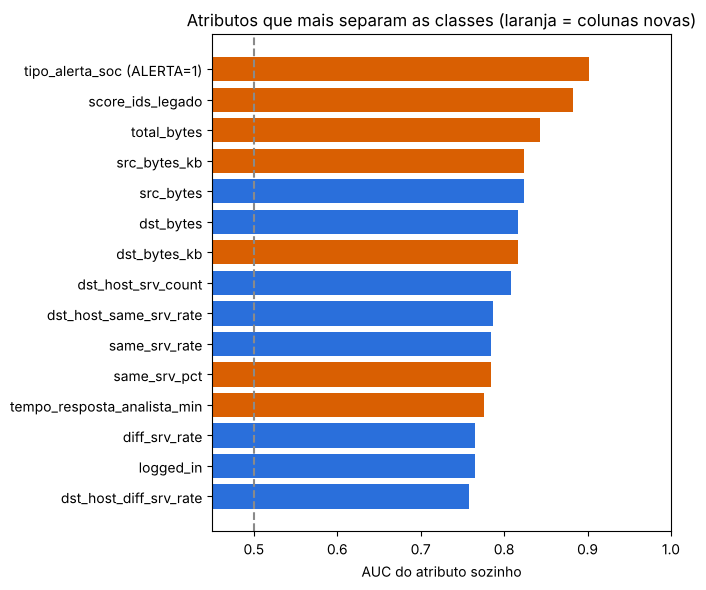

AUC alta com |Pearson| abaixo de 0,2:


,pearson,auc_forte,% ausente
total_bytes,-0.007745,0.843387,39.961050
src_bytes_kb,0.002346,0.823950,39.961050
src_bytes,0.002346,0.823950,39.961050
dst_bytes,-0.003984,0.816695,0.000000
dst_bytes_kb,-0.003984,0.816695,0.000000
dst_host_same_srv_rate,-0.194021,0.786660,0.000000
diff_srv_rate,0.112782,0.765384,4.462074
dst_host_diff_srv_rate,0.030016,0.758412,3.451090


In [19]:
# os 15 atributos que mais separam as classes; em laranja, as colunas novas
top = rel.head(15).iloc[::-1]
cores = [LARANJA if c in NOVAS + ["tipo_alerta_soc (ALERTA=1)"] else AZUL for c in top.index]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top["auc_forte"], color=cores)
ax.axvline(0.5, color=CINZA, ls="--")   # 0,5 = não separa nada
ax.set_xlim(0.45, 1)
ax.set_xlabel("AUC do atributo sozinho")
ax.set_title("Atributos que mais separam as classes (laranja = colunas novas)")
plt.tight_layout(); plt.show()

# atributos que separam bem mas quase não têm correlação: a correlação sozinha não pegaria esses
print("AUC alta com |Pearson| abaixo de 0,2:")
display(rel[rel["|pearson|"] < 0.2].sort_values("auc_forte", ascending=False).head(8)[["pearson", "auc_forte", "% ausente"]])

In [20]:
# olhando as três colunas novas suspeitas, uma por uma, separadas por classe
print("tipo_alerta_soc x classe (treino):")
display(pd.crosstab(treino["tipo_alerta_soc"], treino[ALVO], margins=True))
print("% de ALERTA em cada classe:", treino.groupby(ALVO)["tipo_alerta_soc"].apply(lambda s: (s == "ALERTA").mean() * 100).round(2).to_dict())
print("% de ALERTA no treino:", round((treino["tipo_alerta_soc"] == "ALERTA").mean() * 100, 2),
      "| no teste:", round((teste["tipo_alerta_soc"] == "ALERTA").mean() * 100, 2))

print("\nscore_ids_legado por classe:")
display(treino.groupby(ALVO)["score_ids_legado"].describe())
print("score_ids_legado no teste:")
display(teste["score_ids_legado"].describe().to_frame().T)

print("\ntempo_resposta_analista_min: % de linhas preenchidas em cada classe (treino):")
print(treino.groupby(ALVO)["tempo_resposta_analista_min"].apply(lambda s: s.notna().mean() * 100).round(2).to_dict())
print("% preenchido no treino:", round(treino["tempo_resposta_analista_min"].notna().mean() * 100, 2),
      "| no teste:", round(teste["tempo_resposta_analista_min"].notna().mean() * 100, 2))
print("Tempo médio (quando preenchido), por classe:", treino.groupby(ALVO)["tempo_resposta_analista_min"].mean().round(2).to_dict())

tipo_alerta_soc x classe (treino):


class,anomaly,normal,All
tipo_alerta_soc,,,
ALERTA,3379,1657,5036
OK,700,64097,64797
All,4079,65754,69833


% de ALERTA em cada classe: {'anomaly': 82.84, 'normal': 2.52}
% de ALERTA no treino: 7.21 | no teste: 5.92

score_ids_legado por classe:


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
anomaly,4079.0,0.706873,0.299848,0.0,0.673,0.818,0.904,1.0
normal,65754.0,0.157998,0.174225,0.0,0.057,0.126,0.199,1.0


score_ids_legado no teste:


,count,mean,std,min,25%,50%,75%,max
score_ids_legado,24333.0,0.182446,0.214191,0.0,0.058,0.132,0.21,1.0



tempo_resposta_analista_min: % de linhas preenchidas em cada classe (treino):
{'anomaly': 76.46, 'normal': 4.43}
% preenchido no treino: 8.63 | no teste: 7.4
Tempo médio (quando preenchido), por classe: {'anomaly': 64.7, 'normal': 28.18}


In [21]:
# a falta de valor depende da classe? pra cada coluna com ausentes, comparo a % de ausentes
# nas duas classes, faço um teste qui-quadrado e calculo a AUC do indicador "está ausente"
linhas = []
for c in treino.columns.drop(ALVO):
    aus_c = treino[c].isna()
    if aus_c.sum() == 0:
        continue
    p = chi2_contingency(pd.crosstab(aus_c, treino[ALVO]))[1]
    taxa = aus_c.groupby(treino[ALVO]).mean() * 100
    linhas.append({"coluna": c, "% ausente normal": taxa["normal"], "% ausente anomaly": taxa["anomaly"],
                   "diferença (pp)": taxa["anomaly"] - taxa["normal"], "p-valor": p,
                   "AUC do indicador": auc_atributo(aus_c.astype(int), y)[1]})

miss = pd.DataFrame(linhas).set_index("coluna").sort_values("diferença (pp)", key=abs, ascending=False)
display(miss)
print("Colunas com diferença maior que 5 pontos percentuais:", list(miss.index[miss["diferença (pp)"].abs() > 5]))

,% ausente normal,% ausente anomaly,diferença (pp),p-valor,AUC do indicador
coluna,,,,,
tempo_resposta_analista_min,95.574414,23.535180,-72.039234,0.000000e+00,0.860196
dst_host_serror_rate,29.753323,44.839421,15.086098,2.655159e-91,0.575430
dst_host_same_src_port_rate,28.075859,26.526109,-1.549749,3.388524e-02,0.507749
src_bytes,40.023421,38.955626,-1.067794,1.820257e-01,0.505339
src_bytes_kb,40.023421,38.955626,-1.067794,1.820257e-01,0.505339
total_bytes,40.023421,38.955626,-1.067794,1.820257e-01,0.505339
num_file_creations,5.315266,5.957342,0.642076,8.326840e-02,0.503210
count,5.366974,4.780583,-0.586390,1.137633e-01,0.502932
dst_host_srv_rerror_rate,4.754083,4.216720,-0.537364,1.255429e-01,0.502687


Colunas com diferença maior que 5 pontos percentuais: ['tempo_resposta_analista_min', 'dst_host_serror_rate']


### Disponibilidade de cada coluna no momento da previsão

A pergunta que decide se há vazamento é: quando uma conexão nova chega, essa informação já existe?

| Coluna | Disponível na previsão? | Justificativa |
|---|---|---|
| 41 atributos originais | Sim | São medidos a partir da própria conexão e das conexões recentes. |
| `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct`, `protocolo_cod` | Sim, mas redundantes | São calculadas a partir de colunas que já existem (seção 5). Não vazam informação, apenas a repetem. |
| `score_ids_legado` | Incerto | É a nota de outro sistema de detecção. Se esse sistema funciona em tempo real, a nota estaria disponível; se foi gerada depois, ou com base nos rótulos, seria vazamento. A origem não é documentada. |
| `tipo_alerta_soc` | Provavelmente não | O alerta do SOC é uma classificação feita pela equipe de segurança depois que a conexão chama atenção, ou seja, uma avaliação humana do mesmo problema que o modelo tenta resolver. |
| `tempo_resposta_analista_min` | Não | O tempo de resposta de um analista só existe depois que a conexão foi investigada, e a investigação acontece muito mais nas anomalias. O simples fato de o valor estar preenchido já indica a classe. |

Mesmo que essas colunas estejam presentes no arquivo de teste, usá-las daria um desempenho que não se repetiria em um sistema real.

**Conclusão da seção 6**

- `tipo_alerta_soc` é a coluna mais ligada à classe (AUC 0,90; correlação 0,73): vale `ALERTA` em 82,8% das anomalias e em apenas 2,5% das conexões normais. Por ser uma triagem feita depois do fato, é provavelmente vazamento.
- `tempo_resposta_analista_min` está preenchida em 76,5% das anomalias e em 4,4% das normais, e só o indicador "está ausente" já tem AUC de 0,86. É um caso claro de vazamento, tanto pelo valor quanto pela ausência.
- `score_ids_legado` tem AUC de 0,88 (média de 0,71 nas anomalias e 0,16 nas normais) e nenhum ausente. Pode ser legítima, se o sistema antigo funcionar antes do modelo, mas a origem não é conhecida. A decisão de usá-la precisa ser justificada, e vale comparar os modelos com e sem ela.
- `src_bytes` (AUC 0,82), `dst_bytes` (0,82) e `total_bytes` (0,84) têm correlação de Pearson praticamente nula (abaixo de 0,01), mas separam bem as classes. Se a análise olhasse só a correlação, esses atributos pareceriam inúteis.
- Além de `tempo_resposta_analista_min`, só `dst_host_serror_rate` tem ausência relacionada à classe (44,8% nas anomalias e 29,8% nas normais, AUC do indicador 0,58). Nas demais colunas, a diferença é menor que 2 pontos percentuais.

Na Etapa 2, `tempo_resposta_analista_min` e `tipo_alerta_soc` devem ser removidas. O uso de `score_ids_legado` deve ser decidido e justificado pela equipe, e o indicador de ausência de `dst_host_serror_rate` pode ser avaliado na validação.

## 7. Diagnóstico

| Aspecto | Achado | Ação recomendada para a Etapa 2 |
|---|---|---|
| Desbalanceamento | 5,8% de anomalias (16 normais para cada anomalia); responder sempre "normal" dá acurácia de 0,94 e F1-macro de 0,49 | Validação estratificada; ponderação das classes ou reamostragem só no treino de cada fold; avaliação pelo F1-macro |
| Valores ausentes | 28 colunas com ausentes no treino e no teste, em proporções parecidas | Imputar dentro do pipeline (mediana para numéricas, moda ou categoria "desconhecido" para texto), ajustando só no treino |
| Ausência ligada à classe | `tempo_resposta_analista_min` (95,6% × 23,5%) e `dst_host_serror_rate` (29,8% × 44,8%) | Não usar a ausência de `tempo_resposta_analista_min`; avaliar um indicador para `dst_host_serror_rate` |
| Grafias diferentes | 1.455 linhas em `protocol_type`, 1.340 em `flag` e 1.292 em `service`, só no treino | Normalizar o texto antes de codificar |
| Categorias do teste | Nenhuma categoria nova no teste; 2 serviços só no treino | Codificação que aceite categorias raras ou desconhecidas |
| Valores negativos | 358 em `duration`, 189 em `src_bytes` (e derivadas) e 73 em `total_bytes`, só no treino | Converter em ausente e imputar |
| Taxas fora de [0, 1] | 3.429 valores em 5 colunas, só no treino | Converter em ausente e imputar |
| Contagens acima do máximo | 1.883 valores em `count`, `srv_count` e `dst_host_count`, só no treino | Converter em ausente e imputar |
| `su_attempted = 2` | 49 linhas no treino e 18 no teste, na mesma proporção | Recodificar 2 como 1 ou manter, justificando |
| Duplicatas | 11.355 linhas repetidas no treino; nenhuma no teste | Remover antes de dividir os folds |
| Linhas contraditórias | 1.702 grupos de linhas idênticas com classes diferentes (3.730 linhas) | Remover os grupos ou manter a classe majoritária |
| Coluna constante | `num_outbound_cmds` (no teste, também `is_host_login`) | Remover |
| Colunas copiadas | `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct` e `protocolo_cod` | Remover, mantendo as originais |
| Correlação alta | `serror_rate` e `srv_serror_rate` (r = 0,97) | Considerar em modelos lineares |
| Vazamento | `tempo_resposta_analista_min` (preenchida em 76,5% das anomalias e 4,4% das normais) | Remover |
| Vazamento provável | `tipo_alerta_soc` (`ALERTA` em 82,8% das anomalias e 2,5% das normais) | Remover |
| Coluna de origem incerta | `score_ids_legado` (AUC 0,88) | Decisão da equipe, comparando modelos com e sem ela |
| Atributos mais informativos | `src_bytes`, `dst_bytes` e `dst_host_srv_count` (AUC entre 0,81 e 0,82) | Manter |
| Coluna `id` | Identificador das linhas do teste | Usar apenas para montar o arquivo de submissão |

Em resumo, o treino tem três tipos de problema: dados sujos (grafias, valores impossíveis, duplicatas e linhas contraditórias), redundância (cinco colunas copiadas e uma constante) e vazamento (`tempo_resposta_analista_min`, `tipo_alerta_soc` e a dúvida sobre `score_ids_legado`). Como o teste está bem mais limpo, a limpeza deve ser feita com regras fixas, definidas a partir do treino, e a validação deve ser estratificada, sem duplicatas e avaliada pelo F1-macro.